

<div style="display:flex; justify-content:space-between; align-items:center; margin-bottom:20px;">

<div>

<h1 style="margin:0;"> From Classical Error Correction to Quantum Error Correction  </h1>

<h3 style="margin:5px 0;">Session </h3>

<p style="margin:5px 0;">
<b>Instructor:</b> Harsh Gupta
</p>

<p style="margin:5px 0;">
PhD Researcher  
</p>

<p style="margin:5px 0;">
Department of Electrical Engineering and Computer Science, IISER Bhopal 
</p>

</div>

<!-- <div>
<p align="right">
<img src="figures/csjm-university-logo-big-947x1024.png" width="200">
</p>
</div> -->

<div>
<img src="figures/iiserb_logo.jpg" width="150">
</div>

</div>

<hr>

<p align="center">
<b>Qiskit Fall Fest - IISER Bhopal</b><br>
Date: Oct 2026
</p>
<hr>

## 0. Setup (run once)

This notebook uses **Qiskit** and **Qiskit Aer**, with no IBM account or hardware access needed. If packages are already installed, skip the installation cell. In Jupyter, uncomment the command and run it; restart the kernel if the newly installed packages are not detected.

In [ ]:
# Uncomment if needed (restart kernel after installation):
# %pip install -q "qiskit>=1.2" "qiskit-aer>=0.15" numpy matplotlib

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import qiskit, qiskit_aer

RNG = np.random.default_rng(2026)
simulator = AerSimulator()
print("Qiskit:", qiskit.__version__, "| Aer:", qiskit_aer.__version__)

Qiskit: 2.1.1 | Aer: 0.17.1


## 1. Why do we need error correction? 

Suppose Alice wants to send the bit **1** over a noisy channel. If a transmission flips the bit, Bob receives **0**. A simple remedy is to add *redundancy*:

$$0 \longmapsto 000,\qquad 1\longmapsto 111.$$

Now a single corrupted bit gives, for example, $111\to101$. Bob can still infer that Alice sent 1.

**Think first:** Why is sending the bit three times more reliable than once? When can it fail? How many physical bits are used per information bit?

The code parameters for this **classical** repetition code are $[n,k,d]=[3,1,3]$: three transmitted bits, one information bit, minimum Hamming distance three. It corrects up to $\lfloor(d-1)/2\rfloor=1$ bit flip.

## 2. Classical encoding, noise, and majority decoding 

Define the **Hamming distance** between bit strings as the number of positions in which they differ. The Hamming distance between 000 and 111 is three. Decode a received triple by choosing the closest valid codeword, or equivalently by taking a majority vote.

In [2]:
def encode_classical(bit: int) -> np.ndarray:
    if bit not in (0, 1):
        raise ValueError("bit must be 0 or 1")
    return np.array([bit, bit, bit], dtype=np.uint8)

def binary_symmetric_channel(bits, p, rng=RNG):
    """Independently flip each bit with probability p."""
    bits = np.asarray(bits, dtype=np.uint8)
    flips = (rng.random(bits.shape) < p).astype(np.uint8)
    return bits ^ flips

def majority_decode(received):
    received = np.asarray(received, dtype=np.uint8)
    assert received.shape == (3,)
    return int(np.sum(received) >= 2)

for sent in [0, 1]:
    encoded = encode_classical(sent)
    noisy = encoded.copy()
    noisy[1] ^= 1
    print(f"message={sent}  encoded={encoded}  received={noisy}  decoded={majority_decode(noisy)}")

message=0  encoded=[0 0 0]  received=[0 1 0]  decoded=0
message=1  encoded=[1 1 1]  received=[1 0 1]  decoded=1


**Exercise 1 (2 minutes):** Change the corrupted position from 1 to 0, then 2. What happens if *two* bits flip? Predict before running.

In [3]:
for flips in [(), (0,), (1,), (2,), (0, 2), (0, 1, 2)]:
    r = encode_classical(1)
    for j in flips:
        r[j] ^= 1
    print(f"flipped={str(flips):12s}  received={''.join(map(str, r))}  decoded={majority_decode(r)}")

flipped=()            received=111  decoded=1
flipped=(0,)          received=011  decoded=1
flipped=(1,)          received=101  decoded=1
flipped=(2,)          received=110  decoded=1
flipped=(0, 2)        received=010  decoded=0
flipped=(0, 1, 2)     received=000  decoded=0


### Hamming spheres: why one error is correctable

The valid strings are $000$ and $111$. The sets of strings within Hamming distance one of each codeword do not overlap. Once two bits flip, majority decoding points to the *wrong* codeword.

**Check for understanding:** Which received strings decode to 000? Which decode to 111?

In [3]:
from itertools import product
for triple in product([0, 1], repeat=3):
    r = np.array(triple, dtype=np.uint8)
    d0 = int(np.sum(r != 0))
    d1 = int(np.sum(r != 1))
    print(''.join(map(str, triple)), '->', majority_decode(r), '| distances:', d0, d1)

000 -> 0 | distances: 0 3
001 -> 0 | distances: 1 2
010 -> 0 | distances: 1 2
011 -> 1 | distances: 2 1
100 -> 0 | distances: 1 2
101 -> 1 | distances: 2 1
110 -> 1 | distances: 2 1
111 -> 1 | distances: 3 0


## 3. Parity checks and classical syndromes 

Majority decoding works for the repetition code, but general error-correcting codes use **parity-check equations**. For a three-bit string $r=(r_0,r_1,r_2)^T$, define

$$H=\begin{pmatrix}1&1&0\\0&1&1\end{pmatrix},\qquad s=Hr\pmod 2.$$

Here $s=(s_0,s_1)^T$ is the **syndrome**. Every valid codeword has syndrome $00$. For an error vector $e$, where $r=c+e\pmod 2$,

$$Hr=H(c+e)=Hc+He=He\pmod 2.$$

**Key point:** The syndrome depends on the error pattern, not on which of the two codewords was sent. This is the main bridge to quantum stabilizer measurement.

In [5]:
H = np.array([[1, 1, 0], [0, 1, 1]], dtype=np.uint8)

def syndrome_classical(received):
    return tuple(int(x) for x in (H @ np.asarray(received, dtype=np.uint8)) % 2)

single_error_table = {}
for j in range(3):
    e = np.zeros(3, dtype=np.uint8)
    e[j] = 1
    single_error_table[syndrome_classical(e)] = j
single_error_table[(0, 0)] = None
print("syndrome -> error location:", single_error_table)

def decode_by_syndrome(received):
    r = np.asarray(received, dtype=np.uint8).copy()
    loc = single_error_table[syndrome_classical(r)]
    if loc is not None:
        r[loc] ^= 1
    return r, int(r[0])

for r in [np.array(t, dtype=np.uint8) for t in product((0,1), repeat=3)]:
    corrected, decoded = decode_by_syndrome(r)
    assert decoded == majority_decode(r)
    print(''.join(map(str, r)), 'syndrome', syndrome_classical(r), '->', ''.join(map(str, corrected)))

syndrome -> error location: {(1, 0): 0, (1, 1): 1, (0, 1): 2, (0, 0): None}
000 syndrome (0, 0) -> 000
001 syndrome (0, 1) -> 000
010 syndrome (1, 1) -> 000
011 syndrome (1, 0) -> 111
100 syndrome (1, 0) -> 000
101 syndrome (1, 1) -> 111
110 syndrome (0, 1) -> 111
111 syndrome (0, 0) -> 111


**Exercise 2:** Derive all four syndrome values without code. Which parity check detects a flip on the middle bit? Explain why syndrome 11 does not uniquely identify the error *if multiple bit flips are allowed*.

| Error | $s_0=r_0\oplus r_1$ | $s_1=r_1\oplus r_2$ | Decoder action |
|---|---|---|---|
| $I$ | 0 | 0 | None |
| flip bit 0 | 1 | 0 | flip bit 0 |
| flip bit 1 | 1 | 1 | flip bit 1 |
| flip bit 2 | 0 | 1 | flip bit 2 |

## 4. When does classical repetition coding help? 

Assume independent bit flips with probability $p$. A single unprotected bit fails with probability $p$. The three-bit repetition code fails when **two or three** bits flip:

$$P_{\mathrm{fail}}^{(3)}(p)=\binom32p^2(1-p)+p^3=3p^2-2p^3.$$

For small $p$, failure is approximately $3p^2$ rather than $p$. But redundancy is not free: the encoding uses three channel bits, and at $p=1/2$ it provides no improvement. The comparison is per transmitted logical bit under the stated independent-noise model.

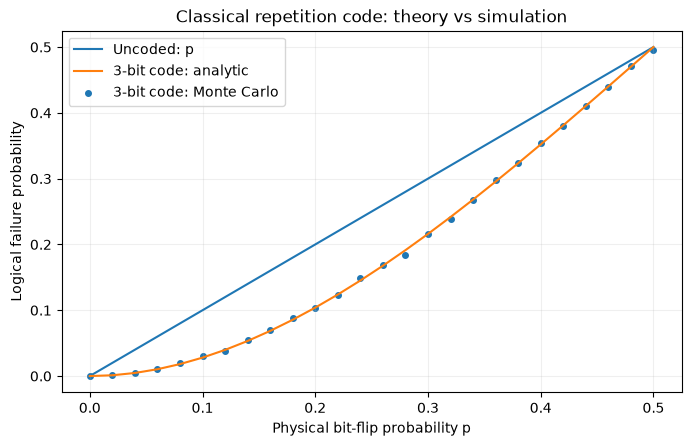

In [6]:
def classical_failure_theory(p):
    p = np.asarray(p)
    return 3 * p**2 - 2 * p**3

def classical_failure_monte_carlo(p, trials=15000, rng=RNG):
    # Assume message 0; by symmetry message 1 has identical failure probability.
    received = (rng.random((trials, 3)) < p)
    return np.mean(np.sum(received, axis=1) >= 2)

ps = np.linspace(0, .5, 26)
empirical = np.array([classical_failure_monte_carlo(p) for p in ps])
plt.figure(figsize=(8, 4.7))
plt.plot(ps, ps, label='Uncoded: p')
plt.plot(ps, classical_failure_theory(ps), label='3-bit code: analytic')
plt.scatter(ps, empirical, s=16, label='3-bit code: Monte Carlo')
plt.xlabel('Physical bit-flip probability p')
plt.ylabel('Logical failure probability')
plt.title('Classical repetition code: theory vs simulation')
plt.legend(); plt.grid(alpha=.2); plt.show()
assert np.allclose(classical_failure_theory(.5), .5)

## 5. Classical vs quantum information 
A bit is either 0 or 1. An unknown qubit can be

$$|\psi\rangle=\alpha|0\rangle+\beta|1\rangle,\quad |\alpha|^2+|\beta|^2=1.$$

A quantum state cannot generally be cloned. The correct quantum repetition encoding is **not**

$$|\psi\rangle\not\longmapsto |\psi\rangle^{\otimes 3}.$$

Instead, two auxiliary data qubits initialized to $|0\rangle$ and two CNOTs implement

$$\alpha|0\rangle+\beta|1\rangle \longmapsto \alpha|000\rangle+\beta|111\rangle.$$

This preserves the unknown amplitudes coherently. You can measure **parities** to learn about errors without measuring the logical value of the unknown state.

**Ask aloud:** Why would measuring all three data qubits in the computational basis destroy a superposition? What might we measure instead?

## 6. Quantum encoding in Qiskit 

Qiskit labels qubits $q_0,q_1,q_2$ but displays basis states in the order $|q_2 q_1 q_0\rangle$. Symmetric $|000\rangle$ and $|111\rangle$ are unaffected by this convention, but interpreting error locations and classical bit strings requires care.

Start with $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$ and encode it.

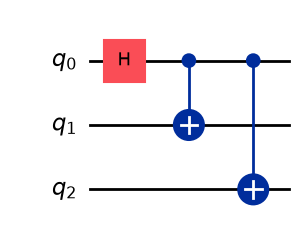

Encoded amplitudes, in |q2 q1 q0> order:
{np.str_('000'): np.complex128(0.7071067811865475+0j), np.str_('111'): np.complex128(0.7071067811865475+0j)}


In [ ]:
def encoder_circuit(prepare='plus'):
    qc = QuantumCircuit(3)
    if prepare == 'plus': qc.h(0)
    elif prepare == 'one': qc.x(0)
    elif prepare == 'zero': pass
    else: raise ValueError('prepare must be plus, zero, or one')
    qc.cx(0, 1)
    qc.cx(0, 2)
    return qc

enc = encoder_circuit('plus')

sv = Statevector.from_instruction(enc)
print('Encoded amplitudes, in |q2 q1 q0> order:')
print(sv.to_dict())
assert np.allclose(np.abs(sv.data[[0, 7]]), 1/np.sqrt(2))
enc.draw()

**Exercise 3:** Replace `plus` with `zero` and `one`. What state do you obtain? Does the encoding use three copies of $|+\rangle$?

For a general input we can use a parameterized one-qubit rotation, giving $\cos(\theta/2)|0\rangle+\sin(\theta/2)|1\rangle$.

In [8]:
theta = np.pi / 3
qc_general = QuantumCircuit(3)
qc_general.ry(theta, 0)
qc_general.cx(0, 1)
qc_general.cx(0, 2)
state = Statevector.from_instruction(qc_general)
print(state.to_dict())
print('Expected:', {'000': np.cos(theta/2), '111': np.sin(theta/2)})

{np.str_('000'): np.complex128(0.8660254037844387+0j), np.str_('111'): np.complex128(0.49999999999999994+0j)}
Expected: {'000': np.float64(0.8660254037844387), '111': np.float64(0.49999999999999994)}


## 7. Measure parity with ancillas, not data qubits 

The bit-flip code has two **$Z$-type stabilizer checks**:

$$S_0=Z_0Z_1,\qquad S_1=Z_1Z_2.$$

A valid encoded state satisfies $S_0|\psi_L\rangle=S_1|\psi_L\rangle=|\psi_L\rangle$. An $X$ on one data qubit anticommutes with one or both checks, changing corresponding eigenvalues from $+1$ to $-1$.

To measure $Z_iZ_j$: initialize an ancilla to $|0\rangle$, apply CNOTs **from each data qubit to the ancilla**, then measure the ancilla. Measurement result 0 means eigenvalue $+1$; result 1 means eigenvalue $-1$.

**Important:** Measuring these checks preserves $\alpha|000\rangle+\beta|111\rangle$ when no error has occurred. They reveal parity, not $\alpha$ or $\beta$.

In [5]:
def syndrome_circuit(error=None, prepare='plus', correct=False, final_data_measure=True):
    """Data q[0:3], ancillas a[0:2], syndrome clbits s[0:2].

    error: None, 0,1,2 (X on that data qubit), or 'Z0' (phase error).
    correct: apply conditional X corrections using measured syndrome.
    """
    q = QuantumRegister(3, 'q')
    a = QuantumRegister(2, 'a')
    s = ClassicalRegister(2, 's')
    out = ClassicalRegister(3, 'out')
    qc = QuantumCircuit(q, a, s, out)
    if prepare == 'plus': qc.h(q[0])
    elif prepare == 'one': qc.x(q[0])
    elif prepare != 'zero': raise ValueError(prepare)
    qc.cx(q[0], q[1]); qc.cx(q[0], q[2])
    qc.barrier()
    if error in [0, 1, 2]: qc.x(q[error])
    elif error == 'Z0': qc.z(q[0])
    elif error is not None: raise ValueError(error)
    qc.barrier()
    qc.cx(q[0], a[0]); qc.cx(q[1], a[0])
    qc.cx(q[1], a[1]); qc.cx(q[2], a[1])
    qc.measure(a, s)
    if correct:
        # Qiskit stores integer s = s0 + 2*s1.
        # s=(1,0)->int 1->X0; (1,1)->int 3->X1; (0,1)->int 2->X2.
        with qc.if_test((s, 1)): qc.x(q[0])
        with qc.if_test((s, 3)): qc.x(q[1])
        with qc.if_test((s, 2)): qc.x(q[2])
    if final_data_measure:
        qc.measure(q, out)
    return qc

example = syndrome_circuit(error=1, prepare='plus', correct=True)
print(example.draw(output='text'))

       ┌───┐           ░       ░                           ┌────── ┌───┐»
  q_0: ┤ H ├──■────■───░───────░───■───────────────────────┤ If-0  ┤ X ├»
       └───┘┌─┴─┐  │   ░ ┌───┐ ░   │                       └──╥─── └───┘»
  q_1: ─────┤ X ├──┼───░─┤ X ├─░───┼────■────■────────────────╫─────────»
            └───┘┌─┴─┐ ░ └───┘ ░   │    │    │                ║         »
  q_2: ──────────┤ X ├─░───────░───┼────┼────┼───────■────────╫─────────»
                 └───┘ ░       ░ ┌─┴─┐┌─┴─┐  │  ┌─┐  │        ║         »
  a_0: ────────────────░───────░─┤ X ├┤ X ├──┼──┤M├──┼────────╫─────────»
                       ░       ░ └───┘└───┘┌─┴─┐└╥┘┌─┴─┐┌─┐   ║         »
  a_1: ────────────────░───────░───────────┤ X ├─╫─┤ X ├┤M├───╫─────────»
                       ░       ░           └───┘ ║ └───┘└╥┘┌──╨──┐      »
  s: 2/══════════════════════════════════════════╩═══════╩═╡ 0x1 ╞══════»
                                                 0       1 └─────┘      »
out: 3/═══════════════════════════════

### Reading measured syndrome strings

When measuring *two* classical registers, Qiskit groups strings in reverse register order. Our circuit creates `s` first and `out` second; results look like `'out2out1out0 s1s0'`. Thus for a middle-qubit error we expect syndrome bits $s_0=s_1=1$, displayed as `11`. For a flip of qubit 0 we expect `01` on the right, not `10`.

We will extract the **last** two characters of the result string as the syndrome. Do not silently confuse the printed order $s_1s_0$ with the mathematical order $(s_0,s_1)$.

In [6]:
simulator = AerSimulator()

for error in [None, 0, 1, 2]:
    circuit = syndrome_circuit(error=error, prepare='zero', correct=False)
    counts = simulator.run(circuit, shots=64).result().get_counts()
    observed = {label.split(' ')[-1] for label in counts}
    print(f'error={str(error):4s} : {counts} -> syndrome printed as s1s0 = {observed}')
    expected = {None:'00', 0:'01', 1:'11', 2:'10'}[error]
    assert observed == {expected}

error=None : {'000 00': 64} -> syndrome printed as s1s0 = {'00'}
error=0    : {'001 01': 64} -> syndrome printed as s1s0 = {'01'}
error=1    : {'010 11': 64} -> syndrome printed as s1s0 = {'11'}
error=2    : {'100 10': 64} -> syndrome printed as s1s0 = {'10'}


## 8. Correct every possible single $X$ error 

Following syndrome measurement, a conditional $X$ on the inferred location restores the encoded state. In this demo, the simulator supports Qiskit **dynamic circuit** `if_test` instructions.

To confirm recovery for an arbitrary superposition without measuring the logical state, apply the inverse encoding circuit (two CNOTs) and measure the decoded first qubit in the $X$ basis. If we began with $|+\rangle$ and correction worked, an $H$ followed by a computational basis measurement should give 0 with certainty.

The other two data qubits should return to $|0\rangle$.

In [11]:
def corrected_plus_test(error):
    qc = syndrome_circuit(error=error, prepare='plus', correct=True,
                          final_data_measure=False)
    # Undo the encoding and test initial |+> state.
    qc.cx(0, 2); qc.cx(0, 1); qc.h(0)
    qc.measure([0, 1, 2], [qc.cregs[1][0], qc.cregs[1][1], qc.cregs[1][2]])
    return qc

for error in [None, 0, 1, 2]:
    counts = simulator.run(corrected_plus_test(error), shots=128).result().get_counts()
    print(f'X error position {error}: {counts}')
    assert all(key.split(' ')[0] == '000' for key in counts)
print('PASS: all single X errors corrected for the encoded |+> state.')

X error position None: {'000 00': 128}
X error position 0: {'000 01': 128}
X error position 1: {'000 11': 128}
X error position 2: {'000 10': 128}
PASS: all single X errors corrected for the encoded |+> state.


**Exercise 4:** Run the test without `correct=True`. Which outputs change? Why is a successful test on $|0\rangle$ alone insufficient to prove that an arbitrary quantum superposition was restored?

## 9. Monte Carlo logical failure: an idealized one-round model 

Now each of the **three data qubits** experiences one independent $X$ error with probability $p$, between *ideal* encoding and *ideal* syndrome extraction. There are no gate errors, ancilla faults, or measurement errors. This is a **phenomenological data-error model**, not a full fault-tolerant circuit simulation.

Rather than running thousands of separate Qiskit jobs, use Qiskit to simulate **eight distinct error patterns**, then sample error-pattern probabilities in NumPy. A logical failure occurs when the corrected state differs by a logical $X_L=X_0X_1X_2$ (two or three physical flips). We will verify the decoder's behavior across all eight patterns using Qiskit, then plot its expected failure rate.

In [12]:
def correction_for_syndrome(s0, s1):
    return {(0,0): None, (1,0):0, (1,1):1, (0,1):2}[(s0,s1)]

def qiskit_pattern_test(pattern, shots=16):
    # Same ancilla syndrome-extraction circuit, now with an arbitrary X pattern.
    q = QuantumRegister(3,'q'); a = QuantumRegister(2,'a')
    s = ClassicalRegister(2,'s'); out = ClassicalRegister(3,'out')
    qc = QuantumCircuit(q,a,s,out)
    qc.cx(q[0],q[1]); qc.cx(q[0],q[2]) # input |0_L>
    for i in range(3):
        if pattern[i]: qc.x(q[i])
    qc.cx(q[0],a[0]); qc.cx(q[1],a[0])
    qc.cx(q[1],a[1]); qc.cx(q[2],a[1])
    qc.measure(a,s)
    with qc.if_test((s,1)): qc.x(q[0])
    with qc.if_test((s,3)): qc.x(q[1])
    with qc.if_test((s,2)): qc.x(q[2])
    qc.cx(q[0],q[2]); qc.cx(q[0],q[1]) # inverse encoder
    qc.measure(q,out)
    counts=simulator.run(qc,shots=shots).result().get_counts()
    decoded={key.split(' ')[0] for key in counts}
    assert decoded <= {'000','001'}
    return decoded == {'001'} # q0 holds decoded logical bit

failure_by_pattern = {}
for bits in product((0,1),repeat=3):
    fail=qiskit_pattern_test(bits)
    failure_by_pattern[bits]=fail
    assert fail == (sum(bits)>=2)
    print('X pattern',bits,'-> logical failure:',fail)
print('All eight error patterns match majority-decoding predictions.')

X pattern (0, 0, 0) -> logical failure: False
X pattern (0, 0, 1) -> logical failure: False
X pattern (0, 1, 0) -> logical failure: False
X pattern (0, 1, 1) -> logical failure: True
X pattern (1, 0, 0) -> logical failure: False
X pattern (1, 0, 1) -> logical failure: True
X pattern (1, 1, 0) -> logical failure: True
X pattern (1, 1, 1) -> logical failure: True
All eight error patterns match majority-decoding predictions.


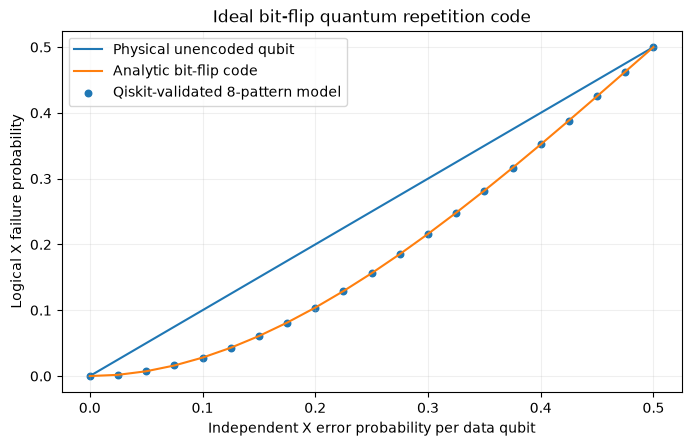

In [13]:
ps = np.linspace(0, .5, 21)
# Exact aggregation of Qiskit-verified responses across all patterns.
qiskit_based = []
for p in ps:
    total = 0.0
    for pattern, fails in failure_by_pattern.items():
        w = sum(pattern)
        total += int(fails) * p**w * (1-p)**(3-w)
    qiskit_based.append(total)
plt.figure(figsize=(8, 4.7))
plt.plot(ps,ps,label='Physical unencoded qubit')
plt.plot(ps,classical_failure_theory(ps),label='Analytic bit-flip code')
plt.scatter(ps,qiskit_based,s=22,label='Qiskit-validated 8-pattern model')
plt.xlabel('Independent X error probability per data qubit')
plt.ylabel('Logical X failure probability')
plt.title('Ideal bit-flip quantum repetition code')
plt.legend(); plt.grid(alpha=.2); plt.show()
assert np.allclose(qiskit_based, classical_failure_theory(ps))

**Discussion:** Why is the curve identical to the classical repetition curve? Which assumptions made that possible? What would happen if the ancilla measurement were wrong or a CNOT propagated a fault?

**Optional advanced homework:** Insert noisy CNOTs and noisy ancilla readout using `qiskit_aer.noise.NoiseModel`. One round of noisy syndrome measurement is **not** automatically fault-tolerant; repeated rounds and a time-aware decoder may be needed.

## 10. The essential limitation: an undetected $Z$ error 

A $Z_0$ error commutes with $Z_0Z_1$ and $Z_1Z_2$. Therefore its syndrome is $(0,0)$, exactly like no error. But it acts nontrivially on the encoded qubit:

$$Z_0(\alpha|000\rangle+\beta|111\rangle)=\alpha|000\rangle-\beta|111\rangle.$$

For $|+_L\rangle$, this turns $|+_L\rangle$ into $|-_L\rangle$. Thus a quantum phase error can be undetected even though computational-basis bit-flip correction looks perfect.

We check the syndrome and the decoded $X$-basis measurement.

In [14]:
for error in [None, 'Z0']:
    qc = syndrome_circuit(error=error, prepare='plus', correct=True, final_data_measure=False)
    qc.cx(0,2); qc.cx(0,1); qc.h(0) # inverse encoding, then X-basis test
    qc.measure([0,1,2],[qc.cregs[1][0],qc.cregs[1][1],qc.cregs[1][2]])
    counts=simulator.run(qc,shots=128).result().get_counts()
    print(f'{error}: {counts}')
    printed_syndromes={k.split(' ')[-1] for k in counts}
    assert printed_syndromes == {'00'}
    expected_data = '000' if error is None else '001'
    assert all(k.split(' ')[0]==expected_data for k in counts)
print('Phase error is invisible to these Z-parity checks, but flips the decoded X-basis outcome.')

None: {'000 00': 128}
Z0: {'001 00': 128}
Phase error is invisible to these Z-parity checks, but flips the decoded X-basis outcome.


### What comes after the three-qubit code?

To diagnose $Z$ errors, one can use $X$-type parity checks or apply Hadamards to switch between $X$ and $Z$ error descriptions. A three-qubit phase-flip repetition code protects against **one $Z$ error** but not all $X$ errors. The nine-qubit Shor code combines ideas to protect against arbitrary single-qubit errors. More generally, quantum stabilizer codes and fault-tolerant syndrome-extraction circuits handle richer error sets and noisy checks.

Do **not** conclude from this notebook that three qubits can correct any arbitrary single-qubit quantum error.

## 11. Exit quiz and take-home challenges

Answer before viewing the short instructor notes:

1. In the classical $[3,1,3]$ code, why does one flipped bit not change the decoded message?
2. For $H=\begin{pmatrix}1&1&0\\0&1&1\end{pmatrix}$, what syndrome results from an error on the middle bit?
3. Why does $\alpha|0\rangle+\beta|1\rangle \mapsto \alpha|000\rangle+\beta|111\rangle$ not violate the no-cloning theorem?
4. Which quantum measurements reveal bit-flip syndromes without revealing $\alpha$ and $\beta$?
5. What is the logical failure probability in the ideal independent-$X$ model?
6. Why do the two checks fail to detect $Z_0$?

**Take-home A:** Write a general classical repetition decoder for odd $n$ and derive its failure probability as a binomial tail.

**Take-home B:** Change the encoded state to an arbitrary $R_y(\theta)|0\rangle$, and verify recovery by applying $R_y(-\theta)$ after inverse encoding.

**Take-home C (advanced):** Add measurement error on syndrome ancillas. Compare one syndrome round with a strategy using repeated rounds; explain carefully what faults your decoder can actually handle.

<details>
<summary><b>Instructor quick answers</b> (expand after quiz)</summary>

1. Valid codewords have Hamming distance 3, and a single flip remains closer to the transmitted word.
2. $(1,1)$.
3. This is an isometric encoding into an entangled code subspace, not three independent copies of the unknown state.
4. Measure $Z_0Z_1$ and $Z_1Z_2$ indirectly using ancillas.
5. $3p^2-2p^3$ under ideal operations and independent data-$X$ noise.
6. $Z_0$ commutes with both stabilizers, so its syndrome is trivial although it changes the logical phase.

</details>

## References and further viewing

- [Provided video lecture (YouTube)](https://www.youtube.com/watch?v=fFOEOukIcUU&t=5s), associated with the John Watrous / IBM Qiskit quantum error-correction material. Treat this as conceptual background, not a claim that the notebook follows its precise timing.
- [IBM Quantum Learning: Classical repetition codes](https://qiskit.qotlabs.org/learning/courses/foundations-of-quantum-error-correction/correcting-quantum-errors/repetition-codes).
- [IBM Quantum: Repetition code tutorial](https://qiskit.qotlabs.org/docs/tutorials/repetition-codes).
- [Qiskit Aer simulator documentation](https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html).
- Nielsen and Chuang, *Quantum Computation and Quantum Information*, chapter on quantum error correction.

